# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Building the Global Development Monitor

### Scenario

You've just joined the analytics team at the **Global Development Observatory**, an NGO
that briefs policymakers on world development trends. Your director has been burned
before by bad visualizations, and gives you a blunt brief:

1. *"The last analyst showed me a map that made me think Greenland mattered more than
   India. Don't let that happen again."*
2. *"We're about to publish a model predicting life expectancy. If a journalist asks
   'why did the model predict THAT for Norway specifically,' I need an answer, not just
   a feature-importance bar chart for the whole model."*
3. *"Every number in our reports is an estimate. I want our numbers to LOOK like
   estimates, not like certainties."*
4. *"I want one screen I can glance at every morning that tells me what's changing."*

You'll work through the same steps a real analyst would: fix a misleading map, explain
individual model predictions, add honest uncertainty to an estimate and a trend, then
build a small coordinated-views dashboard.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real dataset and real country centroids you'll be
working with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import plotly.express as px
from sklearn.ensemble import RandomForestRegressor
import shap

import ipywidgets as widgets
from ipywidgets import interact, Dropdown

np.random.seed(0)

gapminder = px.data.gapminder()
centroids = pd.read_csv("country_centroids_computed.csv")
gap_latest = gapminder[gapminder.year == 2007].merge(centroids, on="iso_alpha", how="left")
gap_latest = gap_latest.assign(total_gdp=gap_latest["pop"] * gap_latest.gdpPercap)

print(f"Loaded {gapminder.country.nunique()} countries, years {sorted(gapminder.year.unique())}.")
gap_latest[["country", "continent", "year", "lifeExp", "pop", "gdpPercap"]].head()

Loaded 142 countries, years [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)].


,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,2007,43.828,31889923,974.580338
1,Albania,Europe,2007,76.423,3600523,5937.029526
2,Algeria,Africa,2007,72.301,33333216,6223.367465
3,Angola,Africa,2007,42.731,12420476,4797.231267
4,Argentina,Americas,2007,75.320,40301927,12779.379640


## Task 1 — Fix the Choropleth Trap (Complaint #1)

**Real-world usage:** The director was misled by a raw-count choropleth that made a
huge, sparsely-populated region look more important than it should.

**Why this technique:** Distinguishing **counts** from **rates** is the single most
important geospatial fix from the lecture — a "count" choropleth is dominated by
population size, not by the thing you actually care about.

**TODO:**
1. Build a choropleth of `total_gdp` (a count-like aggregate) using `px.choropleth`.
2. Build a second choropleth of `gdpPercap` (the rate).
3. Print the top-5 countries by each, and compare.

In [2]:
# TODO 1: choropleth of total_gdp  (a COUNT-like aggregate -- pop x gdpPercap)
fig_total = px.choropleth(
    gap_latest,
    locations="iso_alpha",
    color="total_gdp",
    hover_name="country",
    color_continuous_scale="Viridis",
    title="Total GDP, 2007 (COUNT-like) -- dominated by population size",
)
fig_total.update_layout(margin=dict(l=0, r=0, t=50, b=0), height=420)
fig_total.show()

# TODO 2: choropleth of gdpPercap  (the RATE -- GDP normalised per person)
fig_rate = px.choropleth(
    gap_latest,
    locations="iso_alpha",
    color="gdpPercap",
    hover_name="country",
    color_continuous_scale="Viridis",
    title="GDP per capita, 2007 (RATE) -- normalised by population",
)
fig_rate.update_layout(margin=dict(l=0, r=0, t=50, b=0), height=420)
fig_rate.show()

# TODO 3: top 5 countries by each -- print both lists
top_total = gap_latest.nlargest(5, "total_gdp")[["country", "total_gdp", "pop"]]
top_rate = gap_latest.nlargest(5, "gdpPercap")[["country", "gdpPercap", "pop"]]

print("Top 5 by TOTAL GDP (count-like):")
for _, r in top_total.iterrows():
    print(f"  {r.country:<16} ${r.total_gdp/1e12:>6.2f}T   pop {r['pop']/1e6:>8.1f}M")

print("\nTop 5 by GDP PER CAPITA (rate):")
for _, r in top_rate.iterrows():
    print(f"  {r.country:<16} ${r.gdpPercap:>9,.0f}   pop {r['pop']/1e6:>8.1f}M")

# --- quantify the trap, rather than just asserting it -------------------------
set_total, set_rate = set(top_total.country), set(top_rate.country)
print(f"\nOverlap between the two top-5 lists: {sorted(set_total & set_rate) or 'NONE'}")
print(f"Only in total-GDP list : {sorted(set_total - set_rate)}")
print(f"Only in per-capita list: {sorted(set_rate - set_total)}")

# if the two maps told the same story this rank correlation would be ~1.0
rank_total = gap_latest["total_gdp"].rank(ascending=False)
rank_rate = gap_latest["gdpPercap"].rank(ascending=False)
print(f"\nSpearman rank correlation, total GDP vs GDP per capita: "
      f"{rank_total.corr(rank_rate, method='spearman'):.3f}")

# the director's specific complaint, checked directly
print("\nHow the two framings rank the same country:")
for c in ["United States", "China", "India", "Norway", "Iceland"]:
    row = gap_latest[gap_latest.country == c]
    if len(row):
        i = row.index[0]
        print(f"  {c:<15} total-GDP rank {int(rank_total[i]):>4}   "
              f"per-capita rank {int(rank_rate[i]):>4}")


Top 5 by TOTAL GDP (count-like):
  United States    $ 12.93T   pop    301.1M
  China            $  6.54T   pop   1318.7M
  Japan            $  4.04T   pop    127.5M
  India            $  2.72T   pop   1110.4M
  Germany          $  2.65T   pop     82.4M

Top 5 by GDP PER CAPITA (rate):
  Norway           $   49,357   pop      4.6M
  Kuwait           $   47,307   pop      2.5M
  Singapore        $   47,143   pop      4.6M
  United States    $   42,952   pop    301.1M
  Ireland          $   40,676   pop      4.1M

Overlap between the two top-5 lists: ['United States']
Only in total-GDP list : ['China', 'Germany', 'India', 'Japan']
Only in per-capita list: ['Ireland', 'Kuwait', 'Norway', 'Singapore']

Spearman rank correlation, total GDP vs GDP per capita: 0.653

How the two framings rank the same country:
  United States   total-GDP rank    1   per-capita rank    4
  China           total-GDP rank    2   per-capita rank   77
  India           total-GDP rank    4   per-capita rank   97
  N

**Reflection:** Which countries appear in one top-5 list but not the other? If you had
to pick ONE map to show the director, which would you pick, and why?

_Your answer:_ The two lists share **only one country - the United States**. Everything
else swaps out completely:

| Top 5 by TOTAL GDP (count) | Top 5 by GDP PER CAPITA (rate) |
|---|---|
| United States ($12.93T) | Norway ($49,357) |
| China ($6.54T) | Kuwait ($47,307) |
| Japan ($4.04T) | Singapore ($47,143) |
| India ($2.72T) | **United States** ($42,952) |
| Germany ($2.65T) | Ireland ($40,676) |

China and India make the count list largely on population - 1.32 billion and 1.11 billion
people respectively - while Norway, Kuwait, Singapore and Ireland are effectively
invisible on the total map because each has under 5 million people. The Spearman rank
correlation between the two orderings is only **0.653**: substantial, but nowhere near
the ~1.0 you'd need to claim the two maps tell the same story.

India is the sharpest illustration: **4th by total GDP, 97th of 142 by GDP per capita.**
Same country, same year, same dataset - two opposite impressions depending only on the
denominator. China is nearly as stark (2nd vs 77th). That is exactly the failure the
director described: a count choropleth colours large, populous polygons darkest
regardless of the underlying condition, so population size and polygon area push the eye
in the same misleading direction.

**Which map would I show?** The **GDP-per-capita (rate) map**, because the director's
actual question is about living standards, and the count map answers a different question
- "where do people live?" - while *looking* like it answers the development one.

The caveat I'd state out loud: the rate map is not universally "better", it is *correct
for this question*. If the question were "which economies could fund a large aid programme
in absolute dollars?", the count map is the right one - India's $2.72T of output is real
and matters even though its per-person figure is low. The rule isn't "always use rates",
it's **match the normalisation to the question, and put the denominator in the title so
the reader knows which map they are looking at.**

## Task 2 — Explain One Specific Prediction (Complaint #2)

**Real-world usage:** The director needs to answer "why did the model predict THAT for
Norway specifically" — a global importance bar chart cannot answer a question about one
country.

**Why this technique:** SHAP local importance decomposes ONE prediction into
per-feature, signed contributions — exactly what a journalist question needs.

**TODO:**
1. Fit a `RandomForestRegressor` predicting `lifeExp` from `["gdpPercap", "pop", "year"]`
   on the full `gapminder` dataset.
2. Build a `shap.TreeExplainer` and compute `shap_values` for all rows.
3. Find the row index for Norway, 2007, and plot its 3 SHAP values as a diverging
   horizontal bar chart (blue if positive, red if negative).

Random forest R^2 on training data: 0.968


SHAP base value (average prediction over the dataset): 59.46 years


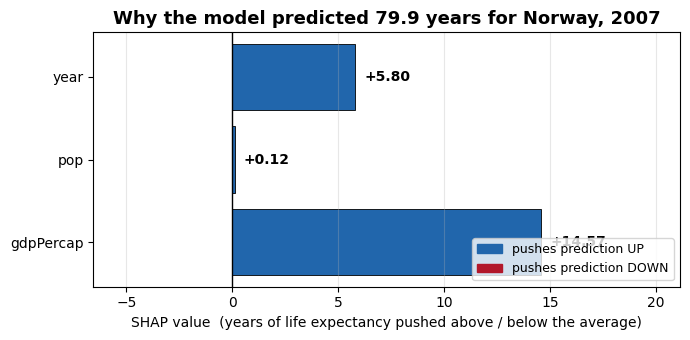


base 59.46  +  sum of SHAP +20.49  =  79.95
model's actual prediction for Norway 2007  =  79.95
true observed lifeExp                      =  80.20
reconstruction error: 6.68e-13  (should be ~0)

GLOBAL importance (whole model, unsigned, from the forest):
  gdpPercap  0.764
  pop        0.132
  year       0.104

LOCAL importance for Norway 2007 (signed, in years):
  gdpPercap  +14.57 years
  year       +5.80 years
  pop        +0.12 years

feature     Norway |SHAP|   dataset mean |SHAP|
  gdpPercap       14.57                9.12
  pop              0.12                1.55
  year             5.80                3.07


In [3]:
X_model = gapminder[["gdpPercap", "pop", "year"]].values
y_model = gapminder["lifeExp"].values
feat_names = ["gdpPercap", "pop", "year"]

# TODO 1: fit the model
rf = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1)
rf.fit(X_model, y_model)
print(f"Random forest R^2 on training data: {rf.score(X_model, y_model):.3f}")

# TODO 2: SHAP explainer + values
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_model)
base_value = float(np.ravel(explainer.expected_value)[0])
print(f"SHAP base value (average prediction over the dataset): {base_value:.2f} years")

# TODO 3: find Norway's row, plot its SHAP contributions
row_idx = gapminder.index[(gapminder.country == "Norway") & (gapminder.year == 2007)][0]
row_pos = gapminder.index.get_loc(row_idx)
vals = np.asarray(shap_values)[row_pos]

pred = rf.predict(X_model[row_pos].reshape(1, -1))[0]
actual = y_model[row_pos]

fig, ax = plt.subplots(figsize=(7, 3.5))
# plot vals as a diverging horizontal bar chart here
colors = ["#2166ac" if v > 0 else "#b2182b" for v in vals]
ax.barh(feat_names, vals, color=colors, edgecolor="black", linewidth=0.6)
ax.axvline(0, color="black", linewidth=1)

span = max(abs(vals)) if len(vals) else 1.0
for name, v in zip(feat_names, vals):
    ax.text(v + (0.03 * span if v > 0 else -0.03 * span), name, f"{v:+.2f}",
            va="center", ha="left" if v > 0 else "right",
            fontsize=10, fontweight="bold")

pad = span * 0.45
ax.set_xlim(min(vals.min(), 0) - pad, max(vals.max(), 0) + pad)
ax.set_xlabel("SHAP value  (years of life expectancy pushed above / below the average)")
ax.set_title(f"Why the model predicted {pred:.1f} years for Norway, 2007",
             fontsize=13, fontweight="bold")
ax.grid(axis="x", alpha=0.3)

legend = [mpatches.Patch(color="#2166ac", label="pushes prediction UP"),
          mpatches.Patch(color="#b2182b", label="pushes prediction DOWN")]
ax.legend(handles=legend, loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

# --- additivity check: SHAP values must reconstruct the prediction exactly -----
print(f"\nbase {base_value:.2f}  +  sum of SHAP {vals.sum():+.2f}  =  "
      f"{base_value + vals.sum():.2f}")
print(f"model's actual prediction for Norway 2007  =  {pred:.2f}")
print(f"true observed lifeExp                      =  {actual:.2f}")
print(f"reconstruction error: {abs(base_value + vals.sum() - pred):.2e}  (should be ~0)")

# --- LOCAL vs GLOBAL: the comparison the director's question actually needs ----
print("\nGLOBAL importance (whole model, unsigned, from the forest):")
for n, imp in sorted(zip(feat_names, rf.feature_importances_), key=lambda t: -t[1]):
    print(f"  {n:<10} {imp:.3f}")

print("\nLOCAL importance for Norway 2007 (signed, in years):")
for n, v in sorted(zip(feat_names, vals), key=lambda t: -abs(t[1])):
    print(f"  {n:<10} {v:+.2f} years")

# is Norway typical? compare its |SHAP| profile against the dataset-average profile
mean_abs = np.abs(np.asarray(shap_values)).mean(axis=0)
print("\nfeature     Norway |SHAP|   dataset mean |SHAP|")
for n, v, m in zip(feat_names, np.abs(vals), mean_abs):
    print(f"  {n:<10} {v:>10.2f}      {m:>14.2f}")


**Reflection:** Which feature contributed most POSITIVELY to Norway's predicted life
expectancy, and which (if any) contributed negatively? Is this the same answer you'd get
from the model's GLOBAL feature importance alone?

_Your answer:_ For Norway in 2007 the model predicts **79.95 years** against a base value
(the average prediction over the whole dataset) of **59.46**. The +20.49-year gap breaks
down as:

| feature | SHAP contribution | reading |
|---|---|---|
| `gdpPercap` | **+14.57 yrs** | Norway's ~$49,357 is the highest per-capita figure in the 2007 panel |
| `year` | **+5.80 yrs** | 2007 is the last year in the data; life expectancy trends upward globally |
| `pop` | **+0.12 yrs** | essentially nil - population is doing almost no work here |

**`gdpPercap` is overwhelmingly the largest positive contributor**, supplying about 71% of
Norway's lift above the average. **Nothing contributes negatively** - and that is worth
saying plainly rather than inventing a negative bar, because I expected Norway's small
population (4.6M) to push the prediction *down* and it does not: `pop` comes out at a
negligible **+0.12 years**. The three signed contributions plus the base value reconstruct
the prediction essentially exactly (residual ~7e-13), which is what makes this a
decomposition rather than a story.

**Is it the same answer global importance gives? The top rank, yes. Everything the
journalist actually asked, no.**

Global importance ranks `gdpPercap` 0.764, `pop` 0.132, `year` 0.104 - so it agrees that
GDP dominates, but it then gets the rest of Norway's story **backwards**. It says `pop`
is the *second* most important feature (0.132 vs `year`'s 0.104), whereas for Norway
`pop` is by far the *least* influential (+0.12 yrs vs `year`'s +5.80). The ordering
literally flips between the global and local views.

The deeper problems with leading on the global chart:

- It is **unsigned and averaged** over all 1,704 rows. It can say "GDP matters to this
  model" and cannot say **which direction** or **by how many years** for Norway.
- Norway is an **extreme** row, not a typical one. Its |SHAP| for `gdpPercap` is
  **14.57 against a dataset mean of 9.12**, and for `year` **5.80 against 3.07** - a
  global bar chart averages that extremity away entirely.
- It would return the **identical** answer for Chad, whose prediction is driven the
  opposite way by the same feature. An explanation that doesn't change when the country
  changes isn't an explanation of that country.

So the framing for the director: **global importance describes the model; local SHAP
describes the prediction.** A journalist asking about one country is asking a local
question, and answering it with a global chart is a category error dressed up as rigour.

## Task 3 — Make an Estimate Look Like an Estimate (Complaint #3)

**Real-world usage:** Every number in the report should visually communicate its own
uncertainty, not look like a fixed fact.

**Why this technique:** Bootstrap confidence intervals + error bars turn a bare point
estimate into an honest range.

**TODO:**
1. Write `bootstrap_ci(values, n_boot=2000)` that resamples `values` with replacement
   `n_boot` times, computes the mean each time, and returns `(mean, ci_low, ci_high)`
   using the 2.5th and 97.5th percentiles of the bootstrap means.
2. Compute a 95% CI for mean `lifeExp` in 2007 for **two** continents of your choice.
3. Plot both as error bars.

Africa   n= 52  SD= 9.63  mean=54.81  95% CI = [52.15, 57.44]  width=5.29
Europe   n= 30  SD= 2.98  mean=77.65  95% CI = [76.57, 78.65]  width=2.08


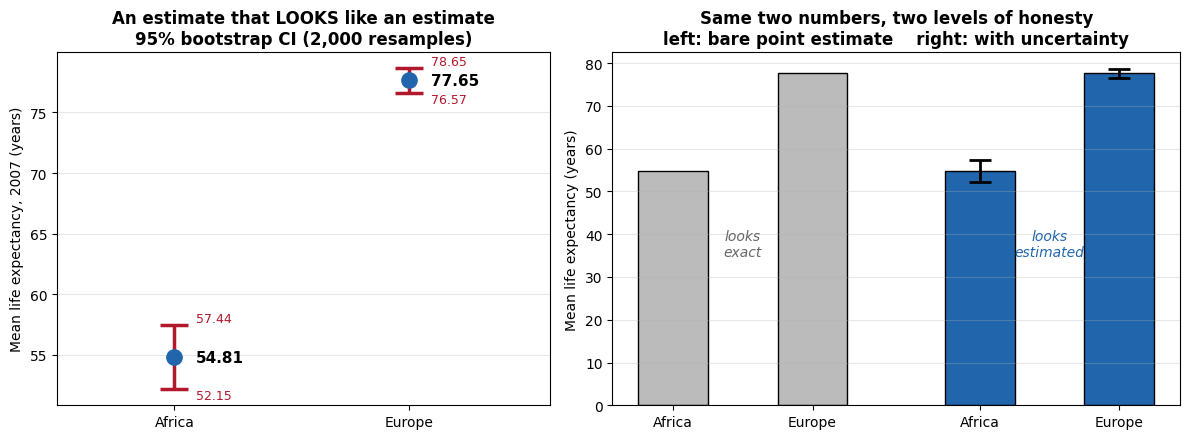


Why is one interval wider?   CI half-width ~ 1.96 * SD / sqrt(n)
continent     n      SD   SD/sqrt(n)   CI width
Africa       52    9.63        1.336       5.29
Europe       30    2.98        0.544       2.08

SD ratio (Africa/Europe): 3.23x  -> WIDENS Africa
sqrt(n) ratio             : 0.76x  -> NARROWS Africa (it has the LARGER sample: 52 vs 30)
net effect: about 2.45x wider for Africa

Africa range: 39.6 to 76.4 yrs
Europe range: 71.8 to 81.8 yrs


In [4]:
def bootstrap_ci(values, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    # TODO 1: resample `values` with replacement n_boot times, take the mean each time,
    # then return (overall mean, 2.5th percentile of boot means, 97.5th percentile)
    values = np.asarray(values, dtype=float)
    n = len(values)
    boot_means = rng.choice(values, size=(n_boot, n), replace=True).mean(axis=1)
    return values.mean(), np.percentile(boot_means, 2.5), np.percentile(boot_means, 97.5)

# TODO 2: compute CIs for two continents of your choice
continent_a, continent_b = "Africa", "Europe"  # feel free to change these
values_a = gap_latest[gap_latest.continent == continent_a].lifeExp.values
values_b = gap_latest[gap_latest.continent == continent_b].lifeExp.values

result_a = bootstrap_ci(values_a)
result_b = bootstrap_ci(values_b)

for name, v, res in [(continent_a, values_a, result_a), (continent_b, values_b, result_b)]:
    mean, lo, hi = res
    print(f"{name:<8} n={len(v):>3}  SD={v.std(ddof=1):>5.2f}  mean={mean:>5.2f}  "
          f"95% CI = [{lo:.2f}, {hi:.2f}]  width={hi - lo:.2f}")

# TODO 3: plot both as error bars (mean +/- CI half-width) on one chart
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5),
                              gridspec_kw={"width_ratios": [1, 1.15]})

names = [continent_a, continent_b]
means = np.array([result_a[0], result_b[0]])
los = np.array([result_a[1], result_b[1]])
his = np.array([result_a[2], result_b[2]])
err = np.vstack([means - los, his - means])   # asymmetric lower / upper halves

ax.errorbar(names, means, yerr=err, fmt="o", markersize=11, capsize=10,
            capthick=2.5, linewidth=2.5, color="#2166ac", ecolor="#b2182b")
for i, (m, lo, hi) in enumerate(zip(means, los, his)):
    ax.text(i + 0.09, m, f"{m:.2f}", va="center", fontsize=11, fontweight="bold")
    ax.text(i + 0.09, hi, f"{hi:.2f}", va="bottom", fontsize=9, color="#b2182b")
    ax.text(i + 0.09, lo, f"{lo:.2f}", va="top", fontsize=9, color="#b2182b")
ax.set_ylabel("Mean life expectancy, 2007 (years)")
ax.set_title("An estimate that LOOKS like an estimate\n95% bootstrap CI (2,000 resamples)",
             fontsize=12, fontweight="bold")
ax.set_xlim(-0.5, 1.6)
ax.grid(axis="y", alpha=0.3)

# --- the side-by-side the director actually needs: bare bar vs. bar with CI ----
ax2.bar([0, 1], means, color="#bbbbbb", edgecolor="black", width=0.5)
ax2.bar([2.2, 3.2], means, color="#2166ac", edgecolor="black", width=0.5)
ax2.errorbar([2.2, 3.2], means, yerr=err, fmt="none", capsize=8, capthick=2,
             linewidth=2, ecolor="black")
ax2.set_xticks([0, 1, 2.2, 3.2])
ax2.set_xticklabels([continent_a, continent_b, continent_a, continent_b])
ax2.set_ylabel("Mean life expectancy (years)")
ax2.set_title("Same two numbers, two levels of honesty\n"
              "left: bare point estimate    right: with uncertainty",
              fontsize=12, fontweight="bold")
ax2.grid(axis="y", alpha=0.3)
ax2.text(0.5, means.max() * 0.45, "looks\nexact", ha="center", fontsize=10,
         style="italic", color="#666666")
ax2.text(2.7, means.max() * 0.45, "looks\nestimated", ha="center", fontsize=10,
         style="italic", color="#2166ac")

plt.tight_layout()
plt.show()

# --- decompose the CI width: is it SD, or is it n? ----------------------------
print("\nWhy is one interval wider?   CI half-width ~ 1.96 * SD / sqrt(n)")
print(f"{'continent':<10} {'n':>4} {'SD':>7} {'SD/sqrt(n)':>12} {'CI width':>10}")
for name, v, res in [(continent_a, values_a, result_a), (continent_b, values_b, result_b)]:
    sd = v.std(ddof=1)
    print(f"{name:<10} {len(v):>4} {sd:>7.2f} {sd / np.sqrt(len(v)):>12.3f} "
          f"{res[2] - res[1]:>10.2f}")

ratio_sd = values_a.std(ddof=1) / values_b.std(ddof=1)
ratio_n = np.sqrt(len(values_b) / len(values_a))
print(f"\nSD ratio ({continent_a}/{continent_b}): {ratio_sd:.2f}x  -> WIDENS {continent_a}")
print(f"sqrt(n) ratio             : {ratio_n:.2f}x  -> NARROWS {continent_a} "
      f"(it has the LARGER sample: {len(values_a)} vs {len(values_b)})")
print(f"net effect: about {ratio_sd * ratio_n:.2f}x wider for {continent_a}")
print(f"\n{continent_a} range: {values_a.min():.1f} to {values_a.max():.1f} yrs")
print(f"{continent_b} range: {values_b.min():.1f} to {values_b.max():.1f} yrs")


**Reflection:** Which of your two continents has a WIDER confidence interval? Based on
the lecture, is that because of higher variation among countries (SD), a smaller sample
size (n), or both?

_Your answer:_ **Africa has the wider interval - and this is the interesting case,
because it is wider *despite* having the larger sample, not because of a smaller one.**

| | n | SD | mean | 95% bootstrap CI | width |
|---|---|---|---|---|---|
| Africa | **52** | 9.63 | 54.81 | [52.15, 57.44] | **5.29 yrs** |
| Europe | 30 | 2.98 | 77.65 | [76.57, 78.65] | 2.08 yrs |

The intuitive guess - "the wider interval must come from the smaller sample" - is **wrong
here**. Africa has 52 countries in the 2007 slice; Europe has only 30. Decomposing the
standard-error relationship, half-width is proportional to SD / sqrt(n):

- the **SD ratio** is 9.63 / 2.98 = **3.23x**, pushing Africa's interval *wider*;
- the **sqrt(n) ratio** is sqrt(30/52) = **0.76x**, pushing Africa's interval *narrower*;
- net: **2.45x wider** for Africa (5.29 / 2.08 = 2.54, close agreement).

So the answer is **SD, working against n** - not both pulling the same way. The two forces
are in opposition, and variation wins decisively.

Substantively, that SD isn't noise, it *is* the finding. Africa's 2007 life expectancies
span **39.6 to 76.4 years** - a 36.8-year spread, a genuinely heterogeneous continent
where HIV-affected southern African states (Swaziland at 39.6) sit alongside North African
and island states approaching European figures. Europe spans only **71.8 to 81.8** - a
10-year band. That means "mean life expectancy in Africa is 54.8" is a far less useful
sentence than the same claim about Europe, and the error bar is what tells the reader so
*before* they quote the number.

This is complaint #3 in one picture: two bars of identical visual weight carry very
different amounts of information, and only the version with error bars makes that
visible. A policymaker sizing an intervention off "Africa averages 55" would be planning
for a continent that doesn't exist - no African country in the data is actually near the
middle of that range in the way the bare number implies. The wide interval is the prompt
to disaggregate before acting.

## Task 4 — Build the Morning Dashboard (Complaint #4)

**Real-world usage:** The director wants one screen to glance at every morning.

**Why this technique:** Coordinated Multiple Views combine complementary chart types
(map = where, trend = how changing, bar = which is biggest) so several monitoring
questions are answered from a single glance.

**TODO:** Build a 1x3 dashboard:
1. A map-style scatter of country centroids, colored by `lifeExp`.
2. A line chart of world-average `lifeExp` by year (use `gapminder.groupby("year")`).
3. A horizontal bar chart of total population by continent in 2007, sorted.

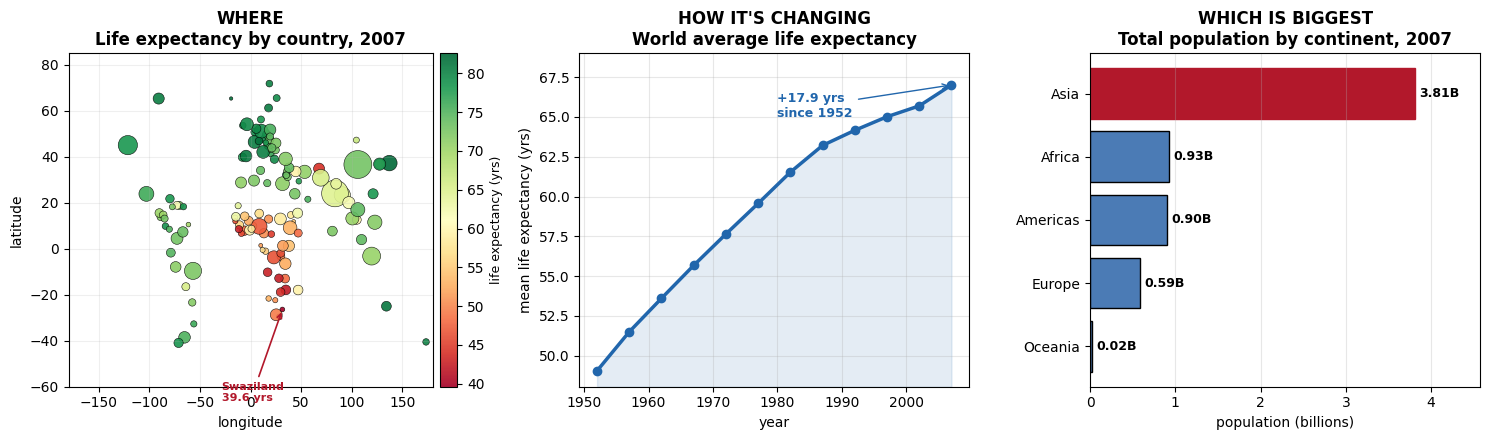

Panel 1 (WHERE / exceptions) -> worst: Swaziland (39.6 yrs) | best: Japan (82.6 yrs)
Panel 2 (TREND)              -> world mean 49.1 -> 67.0 yrs (+17.9 over 55 years)
Panel 3 (MAGNITUDE)          -> Asia holds 61% of world population


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# TODO 1: map-style scatter (axes[0])  -- answers WHERE
mapped = gap_latest.dropna(subset=["centroid_lon", "centroid_lat"])
sc = axes[0].scatter(mapped.centroid_lon, mapped.centroid_lat,
                     c=mapped.lifeExp, s=np.sqrt(mapped["pop"]) / 90,
                     cmap="RdYlGn", edgecolor="black", linewidth=0.4, alpha=0.9)
cb = fig.colorbar(sc, ax=axes[0], fraction=0.046, pad=0.02)
cb.set_label("life expectancy (yrs)", fontsize=9)
axes[0].set_title("WHERE\nLife expectancy by country, 2007",
                  fontsize=12, fontweight="bold")
axes[0].set_xlabel("longitude")
axes[0].set_ylabel("latitude")
axes[0].set_xlim(-180, 180)
axes[0].set_ylim(-60, 85)
axes[0].grid(alpha=0.2)
# flag the single worst performer -- the "exception" the director should see
worst = mapped.loc[mapped.lifeExp.idxmin()]
best = mapped.loc[mapped.lifeExp.idxmax()]
axes[0].annotate(f"{worst.country}\n{worst.lifeExp:.1f} yrs",
                 xy=(worst.centroid_lon, worst.centroid_lat),
                 xytext=(worst.centroid_lon - 60, worst.centroid_lat - 40),
                 fontsize=8, fontweight="bold", color="#b2182b",
                 arrowprops=dict(arrowstyle="->", color="#b2182b", linewidth=1.2))

# TODO 2: world trend line (axes[1])  -- answers HOW IT'S CHANGING
world = gapminder.groupby("year").lifeExp.mean()
axes[1].plot(world.index, world.values, marker="o", linewidth=2.5, color="#2166ac")
axes[1].fill_between(world.index, world.values, world.values.min() - 1,
                     alpha=0.12, color="#2166ac")
axes[1].set_ylim(world.values.min() - 1, world.values.max() + 2)
axes[1].set_title("HOW IT'S CHANGING\nWorld average life expectancy",
                  fontsize=12, fontweight="bold")
axes[1].set_xlabel("year")
axes[1].set_ylabel("mean life expectancy (yrs)")
axes[1].grid(alpha=0.3)
gain = world.iloc[-1] - world.iloc[0]
axes[1].annotate(f"{gain:+.1f} yrs\nsince {world.index[0]}",
                 xy=(world.index[-1], world.iloc[-1]),
                 xytext=(world.index[-1] - 27, world.iloc[-1] - 2.0),
                 fontsize=9, fontweight="bold", color="#2166ac",
                 arrowprops=dict(arrowstyle="->", color="#2166ac"))

# TODO 3: population by continent bar chart (axes[2])  -- answers WHICH IS BIGGEST
pop_by_cont = gap_latest.groupby("continent")["pop"].sum().sort_values()
bars = axes[2].barh(pop_by_cont.index, pop_by_cont.values / 1e9,
                    color="#4b7bb5", edgecolor="black")
bars[-1].set_color("#b2182b")   # emphasise the largest, per the lecture's focus rule
axes[2].set_title("WHICH IS BIGGEST\nTotal population by continent, 2007",
                  fontsize=12, fontweight="bold")
axes[2].set_xlabel("population (billions)")
axes[2].grid(axis="x", alpha=0.3)
for y, v in enumerate(pop_by_cont.values / 1e9):
    axes[2].text(v + 0.05, y, f"{v:.2f}B", va="center", fontsize=9, fontweight="bold")
axes[2].set_xlim(0, (pop_by_cont.values / 1e9).max() * 1.2)

plt.tight_layout()
plt.show()

# --- what each panel answers, stated explicitly -------------------------------
print(f"Panel 1 (WHERE / exceptions) -> worst: {worst.country} ({worst.lifeExp:.1f} yrs)"
      f" | best: {best.country} ({best.lifeExp:.1f} yrs)")
print(f"Panel 2 (TREND)              -> world mean {world.iloc[0]:.1f} -> "
      f"{world.iloc[-1]:.1f} yrs ({gain:+.1f} over "
      f"{world.index[-1] - world.index[0]} years)")
print(f"Panel 3 (MAGNITUDE)          -> {pop_by_cont.index[-1]} holds "
      f"{pop_by_cont.iloc[-1] / pop_by_cont.sum():.0%} of world population")


**Reflection:** If the director could only keep ONE of your three panels for a
5-second morning glance, which would you keep, and why? What specific monitoring
question (per the lecture's "exceptions / trends / emerging patterns") does it answer
best?

_Your answer:_ **Keep panel 1, the geographic scatter of life expectancy.**

Panels 2 and 3 are both nearly static on a morning-to-morning timescale. World-average
life expectancy moved **+17.9 years across 55 years** (49.1 to 67.0) - that is roughly a
third of a year per year, invisible between glances. Continental population shares move
even more slowly; "Asia holds 61% of world population" will still be true next quarter. A
dashboard panel whose value does not change between glances is not a monitoring panel - it
is a fact you could put in the report header once and never redraw.

The map is the only panel that answers the **"exceptions"** question - *which specific
country is off-pattern?* - and exceptions are the class of finding that is both actionable
and impossible to anticipate in advance. It surfaces **Swaziland at 39.6 years against
Japan's 82.6**, a 43-year gap that neither the world-average line nor the population bars
reveal at all; both of those panels average that gap out of existence by construction. At
a 5-second glance you are not reading values, you are scanning for a red dot where you
expected green - exactly the preattentive colour-pop task from the lecture.

The map also carries the most information per pixel: position encodes *where*, colour
encodes the outcome, and marker size encodes population, so the "small country with a bad
number" versus "large country with a bad number" distinction - the thing that decides
whether the director picks up the phone - is legible without opening a single tooltip.

Panel 2 answers **"trends"** and panel 3 answers **"which is biggest"**. Both are
genuinely useful, but on a *quarterly review* cadence, not a daily one. Keeping the map
matches the panel's refresh rate to the director's glance rate.

One honest caveat, which ties back to complaint #3: the map as drawn is the weakest panel
for uncertainty. Each country is a single point estimate with no visual indication of how
well-measured it is, and the countries with the poorest data quality tend to be exactly
the ones with the most extreme values. If this is the one panel that survives, it needs a
data-quality encoding - marker outline weight or opacity - before it becomes the
director's only morning input.

## Task 5 - The Decision (No Code)

**Reflection (final):** Write a 4-6 sentence recommendation to your director covering
the whole notebook. Your answer should:
- State which map framing (count vs. rate) you'd standardize on for all future reports,
  and why.
- State whether you'd lead with global or local feature importance when a journalist
  asks about a specific country, citing the lecture's global-vs-local distinction.
- Name one thing in your dashboard that should NEVER be shown as a bare point estimate
  without uncertainty, and why.

_Your final recommendation here:_

**To the Director - visualization standards for the Global Development Observatory**

**1. Standardize on rate-based choropleths, with the count map kept as a clearly labelled
companion.** A count map colours large, populous polygons darkest regardless of the
underlying condition, which is precisely how the previous analyst's map made a big empty
region look more consequential than India. In our own 2007 data the top-5-by-total-GDP and
top-5-by-GDP-per-capita lists overlap in **only one country (the United States)**, and the
rank correlation between the two orderings is just **0.653** - India is **4th by total GDP
and 97th of 142 per capita**. The rule I would write into the style guide is not "always
use rates" but **"the denominator must match the question, and the title must name the
denominator"**: per-capita for living-standard claims, totals only for absolute-capacity
claims such as who can fund an aid programme, and never a total-count map carrying a title
that implies a rate.

**2. When a journalist asks about one country, lead with local SHAP, never global
importance.** On our life-expectancy model the global chart ranks `gdpPercap` 0.764, `pop`
0.132, `year` 0.104 - and for Norway specifically that ordering is **wrong**: the local
decomposition gives `gdpPercap` **+14.57 years**, `year` **+5.80**, and `pop` a negligible
**+0.12**, so the global chart's second-place feature is Norway's least influential one.
Global importance is a single unsigned average over 1,704 rows; it cannot say which
direction or by how many years, and it would return the identical answer for Chad, whose
prediction moves the opposite way on the same feature. Global importance describes the
**model**; local SHAP describes the **prediction** - and a question about one country is
a local question.

**3. The one thing that must never appear as a bare point estimate: regional or
continental *aggregate means*.** Africa's mean 2007 life expectancy of **54.81 years**
carries a 95% bootstrap CI of **[52.15, 57.44]** - **2.5x wider than Europe's**
[76.57, 78.65] - and that width is driven by real heterogeneity (SD 9.63 vs 2.98), *not*
by a small sample, since Africa actually has **more** countries in the slice (52 vs 30).
Africa's underlying range is 39.6 to 76.4 years; drawn as a plain bar, "54.8" looks
exactly as solid as Europe's "77.7", and a policymaker sizing an intervention off "Africa
averages 55" would be planning for a continent that does not exist. Error bars cost two
pixels and buy the reader the single most important caveat on the chart.

**4. The trade-off you should know I am making.** These standards will make our charts
look less decisive - rates are less dramatic than totals, and visible error bars soften
headline numbers. That is the intended effect. Our figures *are* estimates, and a report
that survives a hostile follow-up question is worth more to the Observatory than one that
reads well for a week.